# TUGAS 2: KLASIFIKASI

Nama: Ratih Kamila Khairani
</p>

<p>
NIM: 055283881
</p>

<p>
Prodi: Sains Data


<p>
Universitas Terbuka adalah sebuah perguruan tinggi terbuka yang memberikan kesempatan bagi putra putri bangsa untuk menimba ilmu dan pengetahuan. UT memiliki mahasiswa dengan latar belakang yang beragam. Mahasiswanya tidak terbatas pada lulusan baru dari sma/smu/smk sederajat. Beberapa diantaranya bahkan telah/sedang bekerja. Kondisi tersebut memberikan kesulitan bagi pihak kampus dalam menerapkan strategi untuk membantu mahasiswa berhasil melewati masa kuliah dan lulus tepat waktu.
</p>

<p>
Sebagai seorang Machine Learning engineer, kamu diminta untuk membuat model yang mampu mendeteksi secara dini tigkat resiko kegagalan seorang mahasiswa. Dengan harapan jika sistem mampu memberikan informasi yang valid, maka bagian wali akademik dapat memberikan konseling yang tepat. Untuk melaksanakan tugasmu ini, kamu diberikan data yang bersumber dari dua periode penerimaan.
</p>


##Task 1


In [ ]:
# Task 1 — Memuat data dari kedua sumber
import pandas as pd
import numpy as np
import matplotlib.pyplot as plt
import seaborn as sns
from pathlib import Path

file_p1 = Path("Data Siswa Periode 1.csv")
file_p2 = Path("Data Siswa Periode 2.csv")

if not (file_p1.exists() and file_p2.exists()):
    try:
        from google.colab import files
        uploaded = files.upload()
        file_p1 = Path("Data Siswa Periode 1.csv")
        file_p2 = Path("Data Siswa Periode 2.csv")
    except Exception as e:
        raise FileNotFoundError(
            "Letakkan Data Siswa Periode 1.csv dan Data Siswa Periode 2.csv "
            "di folder kerja notebook."
        ) from e

data_p1 = pd.read_csv(file_p1)
data_p2 = pd.read_csv(file_p2)

print("Periode 1:", data_p1.shape)
print("Periode 2:", data_p2.shape)
print("\\nKolom Periode 1:")
print(data_p1.columns.tolist())
print("\\nKolom Periode 2:")
print(data_p2.columns.tolist())
display(data_p1.head())
display(data_p2.head())

Periode 1: (1827, 21)
Periode 2: (1730, 21)
\nKolom Periode 1:
['ID', 'Status Pernikahan', 'Program Studi', 'Kelas Reguler/Malam', 'Pendidikan Terakhir', 'Nilai SMA', 'Daerah Asal', 'Pendidikan Ibu', 'Pendidikan Ayah', 'Pekerjaan Ibu', 'Pekerjaan Ayah', 'Nilai Ujian Masuk', 'Pindahan', 'Berkebutuhan Khusus', 'Status pembayaran semester terakhir', 'Jenis Kelamin', 'Beasiswa', 'Usia saat mendaftar', 'IP Semester 1', 'IP Semester 2', 'Target']
\nKolom Periode 2:
['ID', 'Status Pernikahan', 'Program Studi', 'Kelas Siang/Malam', 'Pendidikan Terakhir', 'Nilai SMA', 'Daerah Asal', 'Pendidikan Ibu', 'Pendidikan Ayah', 'Pekerjaan Ibu', 'Pekerjaan Ayah', 'Nilai Ujian Masuk', 'Pindahan', 'Berkebutuhan Khusus', 'Status pembayaran semester terakhir', 'Jenis Kelamin', 'Beasiswa', 'Umur saat mendaftar', 'IP Semester 1', 'IP Semester 2', 'Target']


,ID,Status Pernikahan,Program Studi,Kelas Reguler/Malam,Pendidikan Terakhir,Nilai SMA,Daerah Asal,Pendidikan Ibu,Pendidikan Ayah,Pekerjaan Ibu,...,Nilai Ujian Masuk,Pindahan,Berkebutuhan Khusus,Status pembayaran semester terakhir,Jenis Kelamin,Beasiswa,Usia saat mendaftar,IP Semester 1,IP Semester 2,Target
0,2,Belum Menikah,Teknik Industri,Reguler,SMA/Sederajat,66.55,Pulau Jawa,Dibawah SMA/Sederajat,SMA/Sederajat,Lainnya,...,53.00,Ya,Tidak,Sudah,Pria,Tidak,21,2.48,2.52,Lulus Tepat Waktu
1,3,Belum Menikah,Jurnalistik,Reguler,SMA/Sederajat,63.50,Pulau Jawa,SMA/Sederajat,Lebih dari S1,Pegawai Swasta,...,58.25,Tidak,Tidak,Sudah,Wanita,Ya,19,2.86,2.63,Lulus Tepat Waktu
2,4,Belum Menikah,Pertanian,Reguler,SMA/Sederajat,62.50,Pulau Jawa,Dibawah SMA/Sederajat,SMA/Sederajat,Wiraswasta,...,60.75,Ya,Tidak,Sudah,Pria,Tidak,18,2.20,2.07,Lulus Tidak Tepat Waktu
3,5,Belum Menikah,Teknik Mesin,Reguler,Perguruan Tinggi,75.00,Pulau Jawa,Lebih dari S1,Lebih dari S1,Pegawai Swasta,...,75.00,Tidak,Tidak,Sudah,Wanita,Tidak,20,2.60,2.40,Lulus Tidak Tepat Waktu
4,10,Belum Menikah,Perbankan,Reguler,SMA/Sederajat,65.00,Pulau Jawa,Dibawah SMA/Sederajat,SMA/Sederajat,Pegawai Negri,...,64.55,Ya,Tidak,Sudah,Wanita,Tidak,18,2.61,2.72,Lulus Tepat Waktu


,ID,Status Pernikahan,Program Studi,Kelas Siang/Malam,Pendidikan Terakhir,Nilai SMA,Daerah Asal,Pendidikan Ibu,Pendidikan Ayah,Pekerjaan Ibu,...,Nilai Ujian Masuk,Pindahan,Berkebutuhan Khusus,Status pembayaran semester terakhir,Jenis Kelamin,Beasiswa,Umur saat mendaftar,IP Semester 1,IP Semester 2,Target
0,1817,Belum Menikah,Perbankan,Siang,SMA/Sederajat,66.0,Pulau Jawa,Dibawah SMA/Sederajat,Dibawah SMA/Sederajat,Lainnya,...,62.75,Ya,Tidak,Sudah,Laki-laki,Tidak,18,2.63,2.63,Lulus Tidak Tepat Waktu
1,1819,Belum Menikah,Teknik Industri,Siang,SMA/Sederajat,61.0,Pulau Jawa,Dibawah SMA/Sederajat,Dibawah SMA/Sederajat,Wiraswasta,...,58.55,Ya,Tidak,Sudah,Perempuan,Tidak,19,2.42,0.00,Gagal
2,1820,Belum Menikah,Akuntansi,Siang,SMA/Sederajat,73.5,Pulau Jawa,Lebih dari S1,Lebih dari S1,Lainnya,...,64.40,Tidak,Tidak,Sudah,Perempuan,Tidak,19,2.00,0.00,Gagal
3,1821,Belum Menikah,Perbankan,Siang,SMA/Sederajat,68.0,Pulau Jawa,Dibawah SMA/Sederajat,SMA/Sederajat,Pegawai Negri,...,68.20,Tidak,Tidak,Sudah,Perempuan,Ya,19,2.57,3.10,Lulus Tepat Waktu
4,1822,Belum Menikah,Teknik Industri,Siang,SMA/Sederajat,70.0,Pulau Jawa,Dibawah SMA/Sederajat,Dibawah SMA/Sederajat,Lainnya,...,65.80,Ya,Tidak,Sudah,Laki-laki,Tidak,19,0.00,0.00,Gagal


##Task 2

In [ ]:
# Task 2 — Menyamakan nama fitur yang serupa
print("Kolom yang hanya ada di Periode 1:", sorted(set(data_p1.columns) - set(data_p2.columns)))
print("Kolom yang hanya ada di Periode 2:", sorted(set(data_p2.columns) - set(data_p1.columns)))

data_p1 = data_p1.rename(columns={"Kelas Reguler/Malam": "Kelas", "Usia saat mendaftar": "Usia saat mendaftar"})
data_p2 = data_p2.rename(columns={"Kelas Siang/Malam": "Kelas", "Umur saat mendaftar": "Usia saat mendaftar"})

print("\\nKolom setelah diseragamkan:")
print(data_p1.columns.tolist())
print(data_p2.columns.tolist())

Kolom yang hanya ada di Periode 1: ['Kelas Reguler/Malam', 'Usia saat mendaftar']
Kolom yang hanya ada di Periode 2: ['Kelas Siang/Malam', 'Umur saat mendaftar']
\nKolom setelah diseragamkan:
['ID', 'Status Pernikahan', 'Program Studi', 'Kelas', 'Pendidikan Terakhir', 'Nilai SMA', 'Daerah Asal', 'Pendidikan Ibu', 'Pendidikan Ayah', 'Pekerjaan Ibu', 'Pekerjaan Ayah', 'Nilai Ujian Masuk', 'Pindahan', 'Berkebutuhan Khusus', 'Status pembayaran semester terakhir', 'Jenis Kelamin', 'Beasiswa', 'Usia saat mendaftar', 'IP Semester 1', 'IP Semester 2', 'Target']
['ID', 'Status Pernikahan', 'Program Studi', 'Kelas', 'Pendidikan Terakhir', 'Nilai SMA', 'Daerah Asal', 'Pendidikan Ibu', 'Pendidikan Ayah', 'Pekerjaan Ibu', 'Pekerjaan Ayah', 'Nilai Ujian Masuk', 'Pindahan', 'Berkebutuhan Khusus', 'Status pembayaran semester terakhir', 'Jenis Kelamin', 'Beasiswa', 'Usia saat mendaftar', 'IP Semester 1', 'IP Semester 2', 'Target']


##Task 3


In [ ]:
# Task 3 — Menyamakan kodefikasi kategori dan menggabungkan data
# Normalisasi label kategori agar kedua periode menggunakan kode yang konsisten.
def normalisasi_kategori(df):
    df = df.copy()
    pemetaan = {
        "Kelas": {"Reguler": "Siang", "Siang": "Siang", "Malam": "Malam"},
        "Jenis Kelamin": {
            "Pria": "Laki-laki", "Laki-laki": "Laki-laki",
            "Wanita": "Perempuan", "Perempuan": "Perempuan"
        },
        "Pindahan": {"Ya": "Ya", "Tidak": "Tidak"},
        "Beasiswa": {"Ya": "Ya", "Tidak": "Tidak"},
        "Berkebutuhan Khusus": {"Ya": "Ya", "Tidak": "Tidak"},
        "Status pembayaran semester terakhir": {"Sudah": "Sudah", "Belum": "Belum"},
    }
    for kolom, mapping in pemetaan.items():
        if kolom in df.columns:
            df[kolom] = df[kolom].replace(mapping)
    return df

data_p1 = normalisasi_kategori(data_p1)
data_p2 = normalisasi_kategori(data_p2)

# Periksa struktur kolom sudah sama atau belum, lalu gabungkan baris.
kolom_bersama = sorted(set(data_p1.columns).intersection(data_p2.columns))
data = pd.concat([data_p1[kolom_bersama], data_p2[kolom_bersama]], ignore_index=True)

print("Ukuran data gabungan:", data.shape)
print("\\nDistribusi target:")
display(data["Target"].value_counts().to_frame("Jumlah"))
display(data.head())

Ukuran data gabungan: (3557, 21)
\nDistribusi target:


,Jumlah
Target,
Lulus Tepat Waktu,1757
Gagal,1155
Lulus Tidak Tepat Waktu,645


,Beasiswa,Berkebutuhan Khusus,Daerah Asal,ID,IP Semester 1,IP Semester 2,Jenis Kelamin,Kelas,Nilai SMA,Nilai Ujian Masuk,...,Pekerjaan Ibu,Pendidikan Ayah,Pendidikan Ibu,Pendidikan Terakhir,Pindahan,Program Studi,Status Pernikahan,Status pembayaran semester terakhir,Target,Usia saat mendaftar
0,Tidak,Tidak,Pulau Jawa,2,2.48,2.52,Laki-laki,Siang,66.55,53.00,...,Lainnya,SMA/Sederajat,Dibawah SMA/Sederajat,SMA/Sederajat,Ya,Teknik Industri,Belum Menikah,Sudah,Lulus Tepat Waktu,21
1,Ya,Tidak,Pulau Jawa,3,2.86,2.63,Perempuan,Siang,63.50,58.25,...,Pegawai Swasta,Lebih dari S1,SMA/Sederajat,SMA/Sederajat,Tidak,Jurnalistik,Belum Menikah,Sudah,Lulus Tepat Waktu,19
2,Tidak,Tidak,Pulau Jawa,4,2.20,2.07,Laki-laki,Siang,62.50,60.75,...,Wiraswasta,SMA/Sederajat,Dibawah SMA/Sederajat,SMA/Sederajat,Ya,Pertanian,Belum Menikah,Sudah,Lulus Tidak Tepat Waktu,18
3,Tidak,Tidak,Pulau Jawa,5,2.60,2.40,Perempuan,Siang,75.00,75.00,...,Pegawai Swasta,Lebih dari S1,Lebih dari S1,Perguruan Tinggi,Tidak,Teknik Mesin,Belum Menikah,Sudah,Lulus Tidak Tepat Waktu,20
4,Tidak,Tidak,Pulau Jawa,10,2.61,2.72,Perempuan,Siang,65.00,64.55,...,Pegawai Negri,SMA/Sederajat,Dibawah SMA/Sederajat,SMA/Sederajat,Ya,Perbankan,Belum Menikah,Sudah,Lulus Tepat Waktu,18


##Task 4

In [ ]:
# Task 4 — Mengidentifikasi dan menangani missing/null value
missing_awal = data.isna().sum().sort_values(ascending=False)
display(missing_awal[missing_awal > 0].to_frame("Jumlah missing"))

# Nilai numerik diisi dengan median; kategori diisi dengan modus.
# Pengisian dilakukan sebelum pemodelan agar tidak membuang banyak data.
data_bersih = data.copy()
kolom_numerik_awal = data_bersih.select_dtypes(include=np.number).columns.tolist()
kolom_kategori_awal = data_bersih.select_dtypes(exclude=np.number).columns.tolist()

for kolom in kolom_numerik_awal:
    data_bersih[kolom] = data_bersih[kolom].fillna(data_bersih[kolom].median())
for kolom in kolom_kategori_awal:
    if data_bersih[kolom].isna().any():
        modus = data_bersih[kolom].mode(dropna=True)
        nilai_pengganti = modus.iloc[0] if not modus.empty else "Tidak diketahui"
        data_bersih[kolom] = data_bersih[kolom].fillna(nilai_pengganti)

print("Total missing sebelum penanganan:", int(missing_awal.sum()))
print("Total missing sesudah penanganan:", int(data_bersih.isna().sum().sum()))
print("Ukuran data setelah penanganan missing:", data_bersih.shape)

,Jumlah missing
Daerah Asal,3
Kelas,3


Total missing sebelum penanganan: 6
Total missing sesudah penanganan: 0
Ukuran data setelah penanganan missing: (3557, 21)


##Task 5

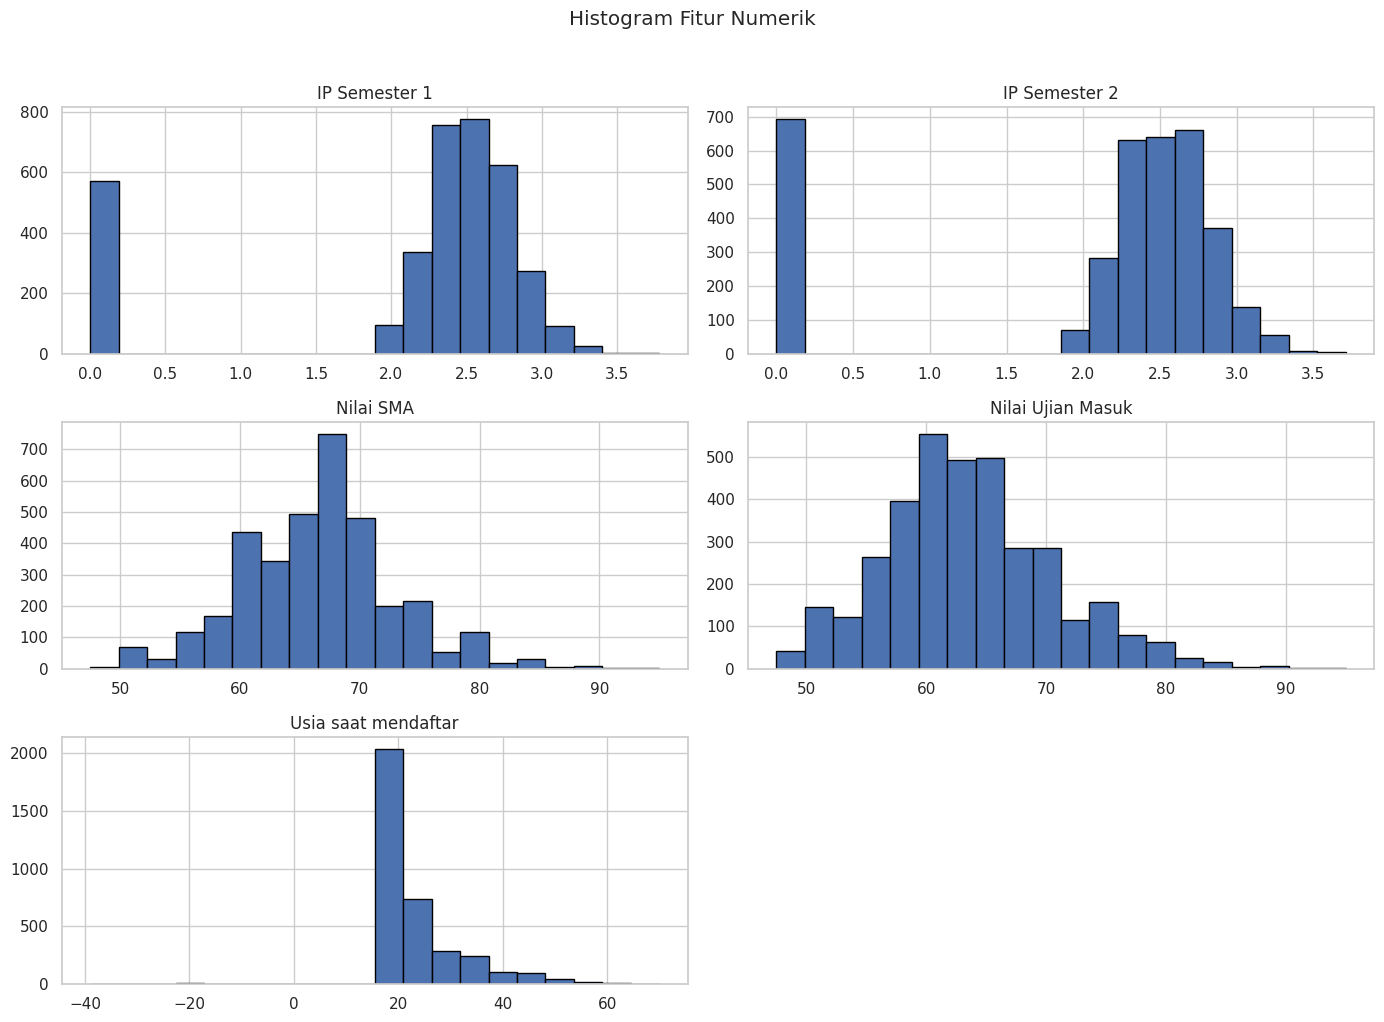

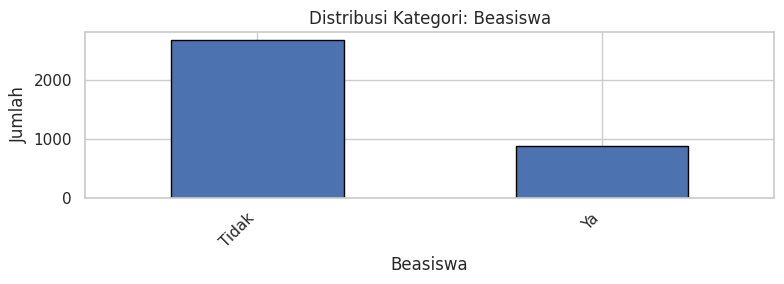

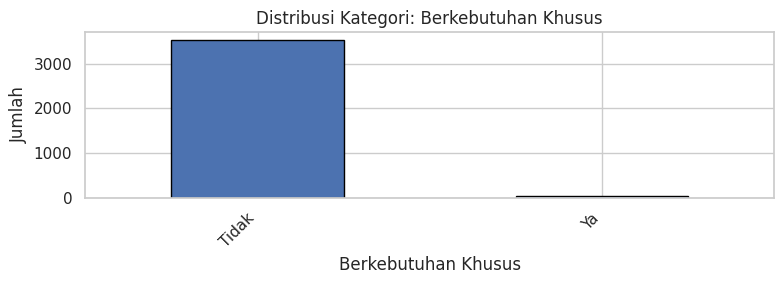

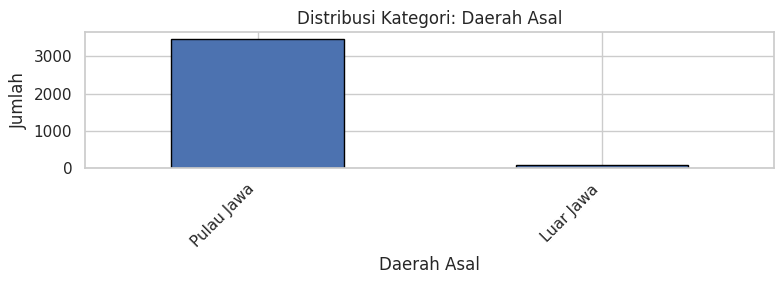

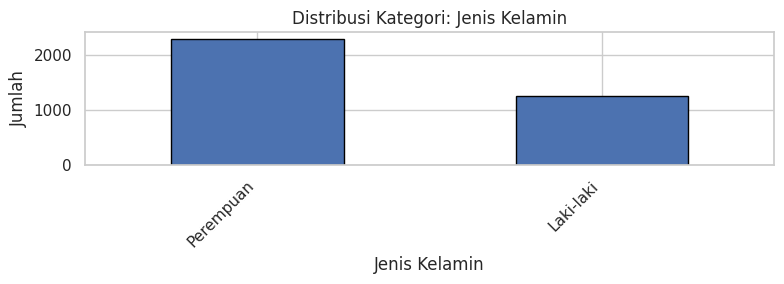

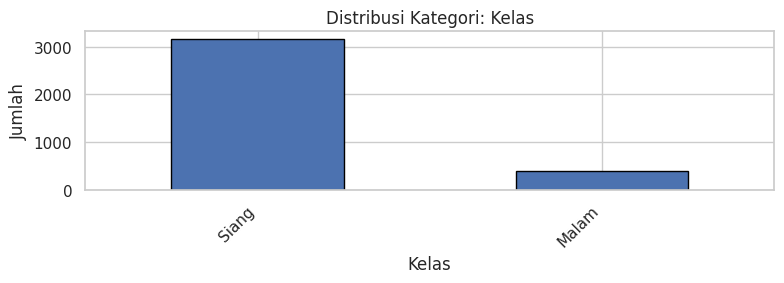

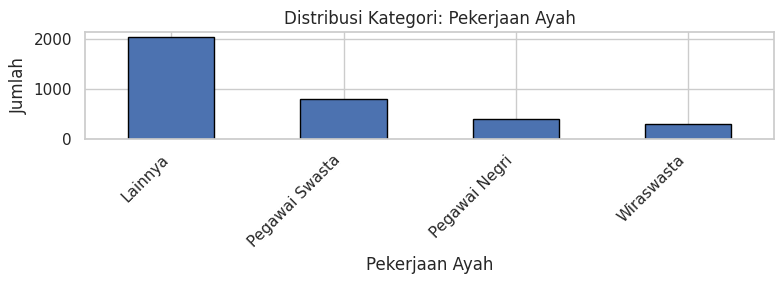

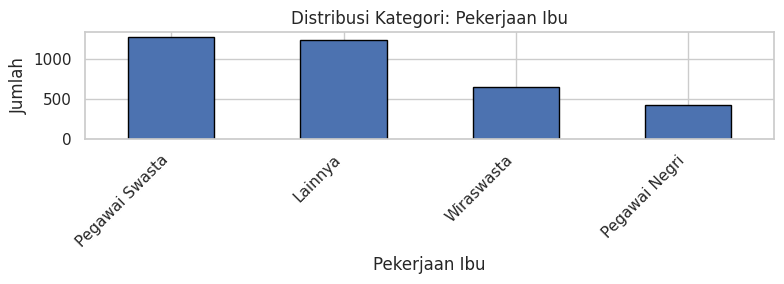

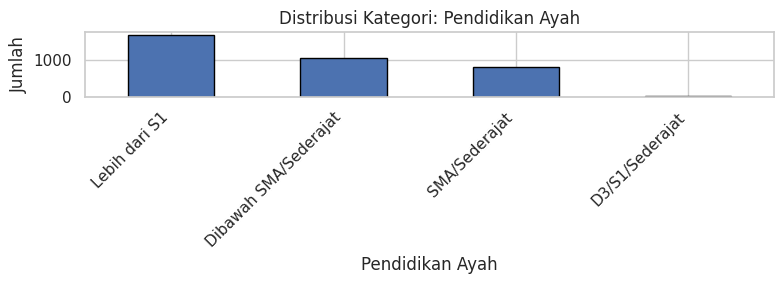

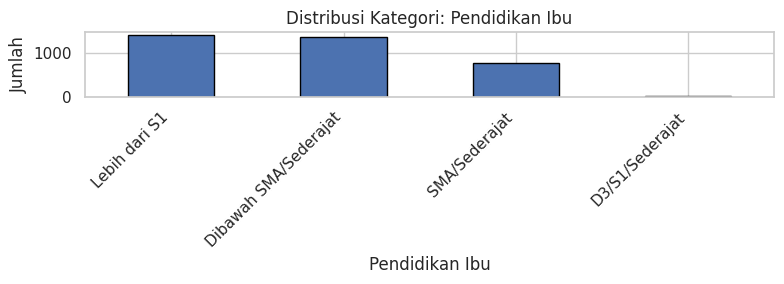

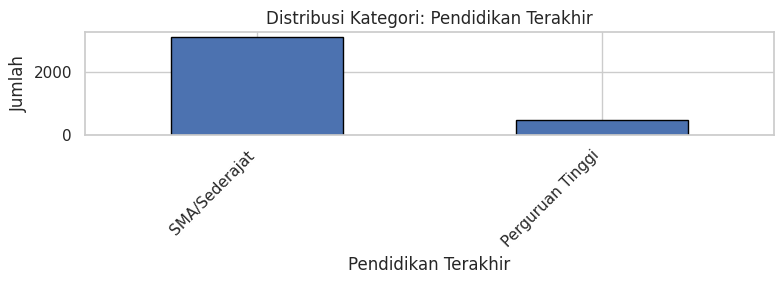

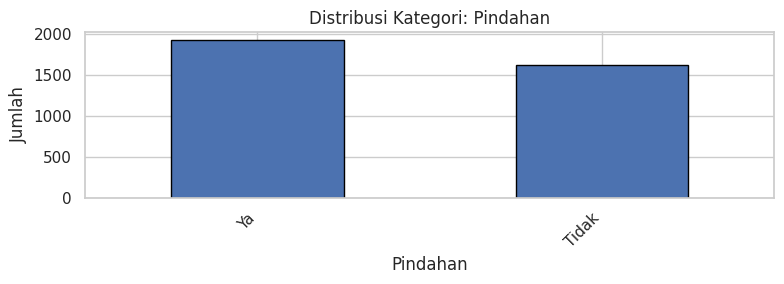

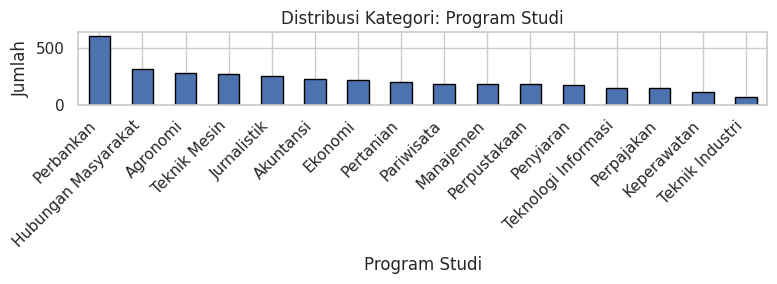

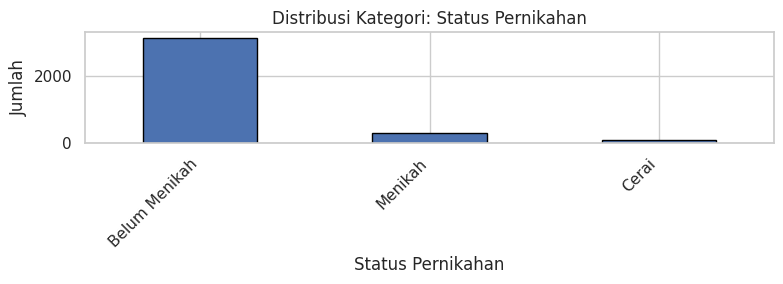

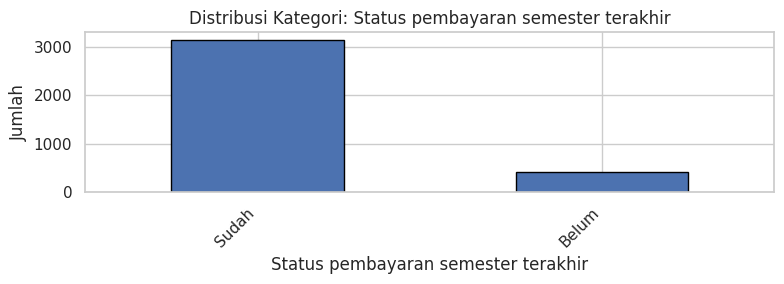

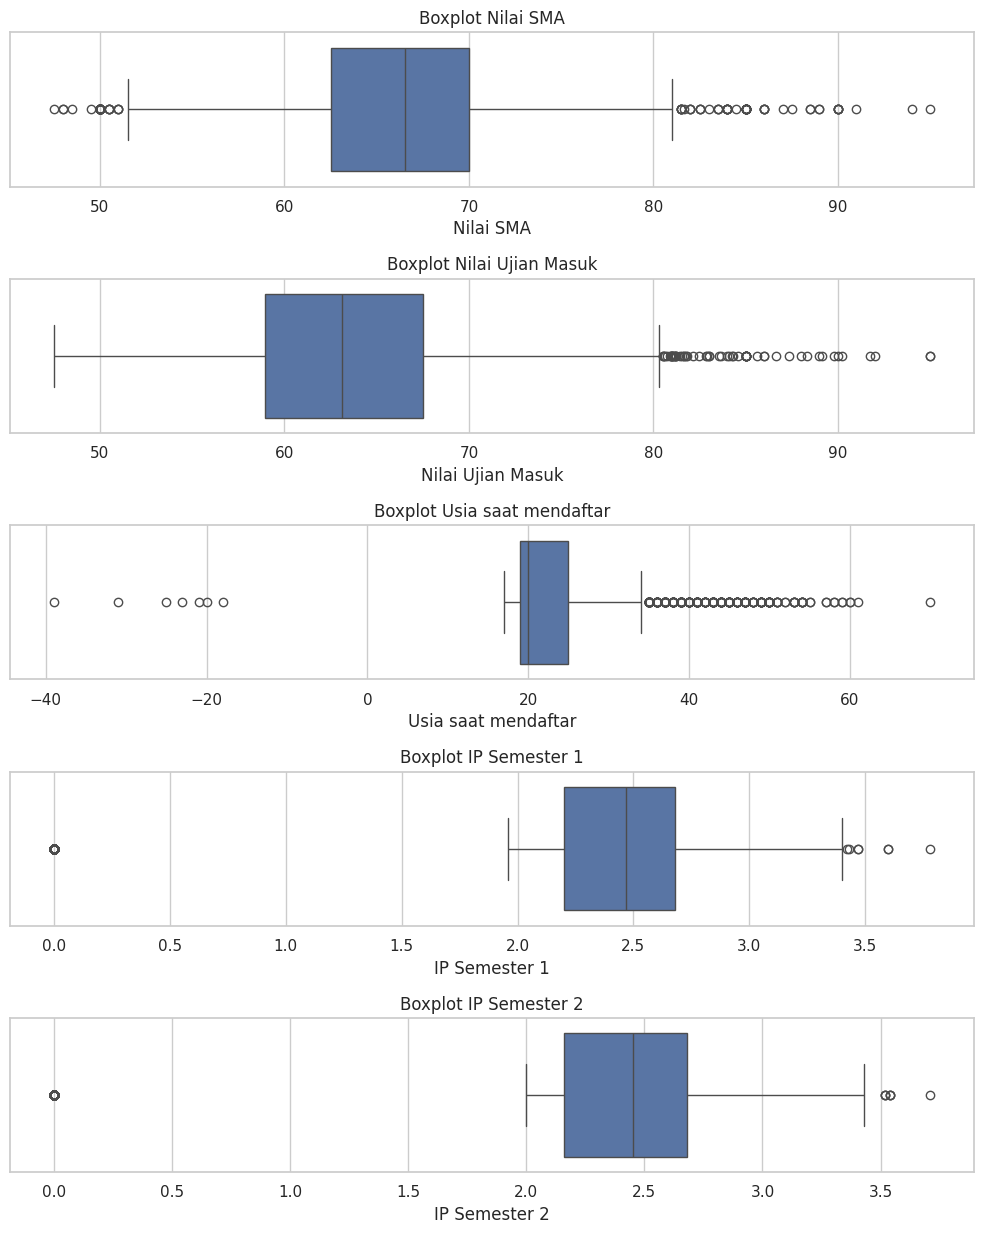

,Fitur,Batas bawah,Batas atas,Jumlah outlier
0,Nilai SMA,51.250,81.250,133
1,Nilai Ujian Masuk,46.125,80.325,61
2,Usia saat mendaftar,10.000,34.000,360


Jumlah baris yang dihapus sebagai outlier pada fitur nilai/usia: 482
Ukuran data setelah penanganan outlier: (3075, 21)
Catatan: pemeriksaan outlier ini hanya memakai Nilai SMA, Nilai Ujian Masuk, dan Usia.


In [ ]:
# Task 5 — Histogram, boxplot, dan penanganan outlier
sns.set_theme(style="whitegrid")

# Histogram untuk setiap fitur numerik, ditampilkan sebagai grafik.
fitur_numerik = data_bersih.select_dtypes(include=np.number).columns.tolist()
fitur_numerik = [c for c in fitur_numerik if c != "ID"]
data_bersih[fitur_numerik].hist(figsize=(14, 10), bins=20, edgecolor="black")
plt.suptitle("Histogram Fitur Numerik", y=1.02)
plt.tight_layout()
plt.show()

# Grafik batang distribusi fitur kategorikal.
fitur_kategori = [c for c in data_bersih.select_dtypes(exclude=np.number).columns if c != "Target"]
for kolom in fitur_kategori:
    plt.figure(figsize=(8, 3))
    data_bersih[kolom].value_counts().plot(kind="bar", edgecolor="black")
    plt.title(f"Distribusi Kategori: {kolom}")
    plt.ylabel("Jumlah")
    plt.xticks(rotation=45, ha="right")
    plt.tight_layout()
    plt.show()

# Boxplot untuk fitur numerik yang relevan.
fitur_box = [c for c in ["Nilai SMA", "Nilai Ujian Masuk", "Usia saat mendaftar",
                          "IP Semester 1", "IP Semester 2"] if c in data_bersih.columns]
fig, axes = plt.subplots(len(fitur_box), 1, figsize=(10, 2.5 * len(fitur_box)))
if len(fitur_box) == 1:
    axes = [axes]
for ax, kolom in zip(axes, fitur_box):
    sns.boxplot(x=data_bersih[kolom], ax=ax)
    ax.set_title(f"Boxplot {kolom}")
plt.tight_layout()
plt.show()

# Deteksi outlier IQR pada nilai ujian dan usia. IP semester 2 bernilai 0
# tidak dihapus karena dapat menjadi sinyal valid untuk mahasiswa yang gagal.
kolom_deteksi = [c for c in ["Nilai SMA", "Nilai Ujian Masuk", "Usia saat mendaftar"] if c in data_bersih.columns]
mask_outlier = pd.Series(False, index=data_bersih.index)
ringkasan_outlier = []
for kolom in kolom_deteksi:
    q1 = data_bersih[kolom].quantile(0.25)
    q3 = data_bersih[kolom].quantile(0.75)
    iqr = q3 - q1
    bawah, atas = q1 - 1.5 * iqr, q3 + 1.5 * iqr
    mask_kolom = (data_bersih[kolom] < bawah) | (data_bersih[kolom] > atas)
    ringkasan_outlier.append({"Fitur": kolom, "Batas bawah": bawah, "Batas atas": atas,
                              "Jumlah outlier": int(mask_kolom.sum())})
    mask_outlier |= mask_kolom
display(pd.DataFrame(ringkasan_outlier))

jumlah_sebelum = len(data_bersih)
data_bersih = data_bersih.loc[~mask_outlier].reset_index(drop=True)
print(f"Jumlah baris yang dihapus sebagai outlier pada fitur nilai/usia: {jumlah_sebelum-len(data_bersih)}")
print("Ukuran data setelah penanganan outlier:", data_bersih.shape)
print("Catatan: pemeriksaan outlier ini hanya memakai Nilai SMA, Nilai Ujian Masuk, dan Usia.")

##Task 6

Rangkuman target:


,Jumlah
Target,
Lulus Tepat Waktu,1564
Gagal,926
Lulus Tidak Tepat Waktu,585


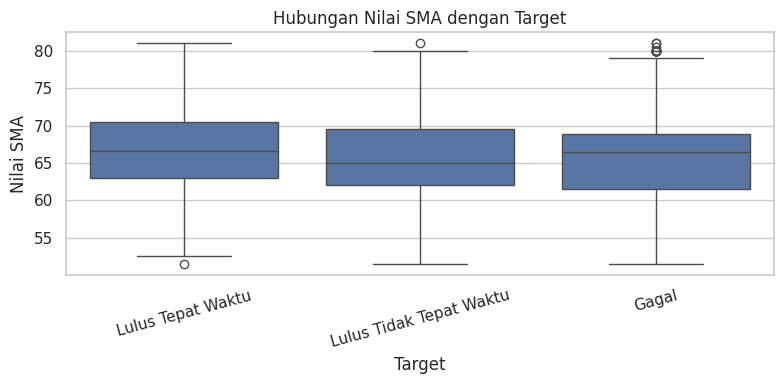

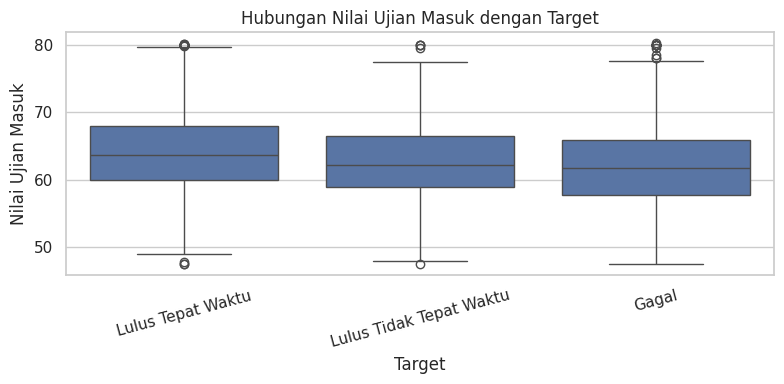

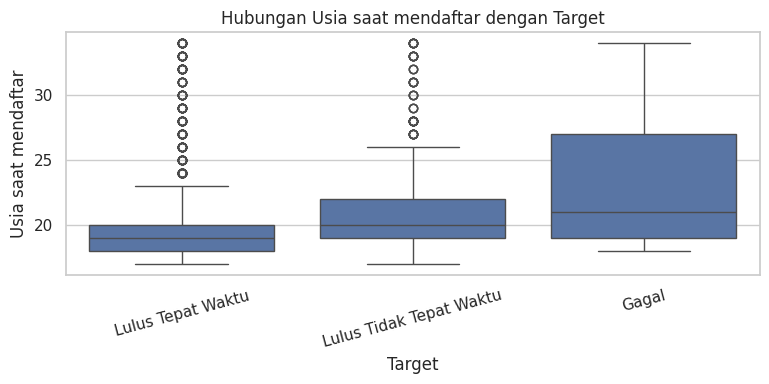

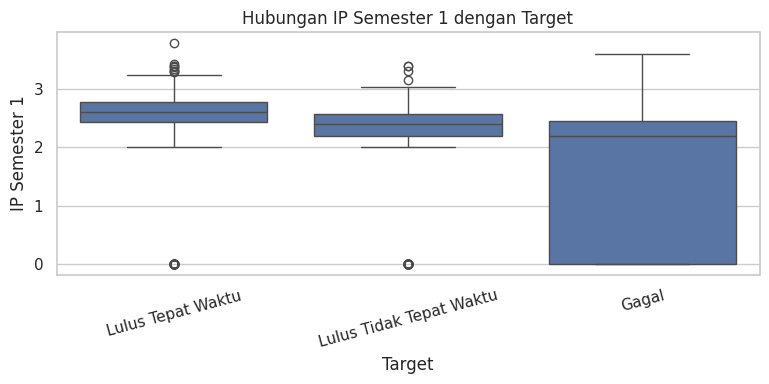

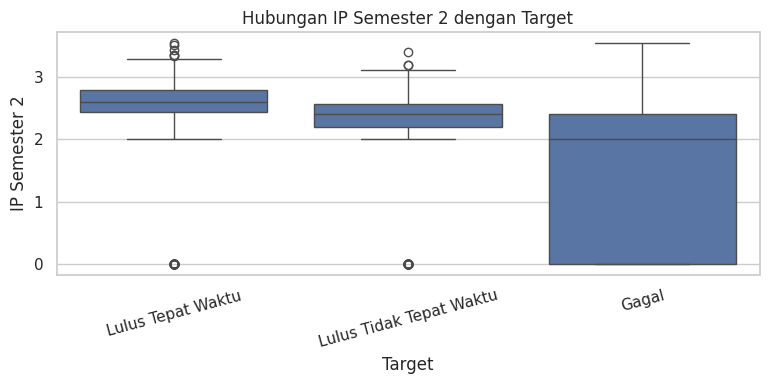

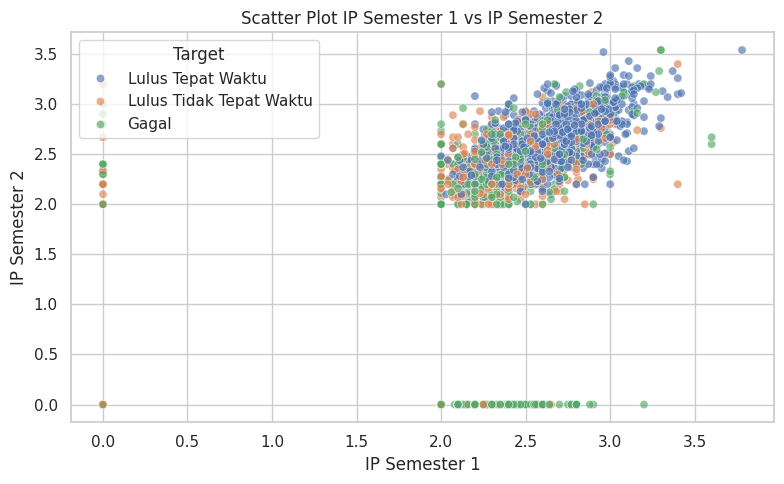

,IP Semester 1,IP Semester 2,Nilai SMA,Nilai Ujian Masuk,Usia saat mendaftar
IP Semester 1,1.000,0.838,0.077,0.096,-0.170
IP Semester 2,0.838,1.000,0.083,0.113,-0.199
Nilai SMA,0.077,0.083,1.000,0.627,-0.046
Nilai Ujian Masuk,0.096,0.113,0.627,1.000,-0.066
Usia saat mendaftar,-0.170,-0.199,-0.046,-0.066,1.000


In [ ]:
# Task 6 — Analisis bivariat dan plot sebaran
print("Rangkuman target:")
display(data_bersih["Target"].value_counts().to_frame("Jumlah"))

# Hubungan fitur numerik dengan target: boxplot per kelas.
for kolom in ["Nilai SMA", "Nilai Ujian Masuk", "Usia saat mendaftar",
              "IP Semester 1", "IP Semester 2"]:
    if kolom in data_bersih.columns:
        plt.figure(figsize=(8, 4))
        sns.boxplot(data=data_bersih, x="Target", y=kolom)
        plt.title(f"Hubungan {kolom} dengan Target")
        plt.xticks(rotation=15)
        plt.tight_layout()
        plt.show()

# Scatter plot untuk melihat hubungan IP semester 1 dan 2 berdasarkan kelas target.
plt.figure(figsize=(8, 5))
sns.scatterplot(data=data_bersih, x="IP Semester 1", y="IP Semester 2",
                hue="Target", alpha=0.65)
plt.title("Scatter Plot IP Semester 1 vs IP Semester 2")
plt.tight_layout()
plt.show()

# Korelasi numerik sebagai pelengkap eksplorasi.
display(data_bersih.select_dtypes(include=np.number).drop(columns=["ID"], errors="ignore").corr().round(3))

## Task 7 — Ketidakseimbangan kelas

Target terdiri dari tiga kelas: **Lulus Tepat Waktu**, **Lulus Tidak Tepat Waktu**, dan **Gagal**. Karena jumlah kelas tidak sama, digunakan algoritma **Random Forest Classifier** dengan `class_weight='balanced'`. Dengan pendekatan ini, bobot kelas yang lebih jarang dinaikkan sehingga tidak perlu membuat data sintetis/augmentasi. Pemisahan data dilakukan secara stratified agar proporsi target tetap terjaga.

In [ ]:
# Tidak melakukan augmentasi data; penanganan ketidakseimbangan dilakukan
# melalui class_weight='balanced' pada model Random Forest.
print("Distribusi kelas sebelum pembagian data:")
display(data_bersih["Target"].value_counts().to_frame("Jumlah"))
print("Strategi balancing: class_weight='balanced'; augmentasi data tidak dilakukan.")

Distribusi kelas sebelum pembagian data:


,Jumlah
Target,
Lulus Tepat Waktu,1564
Gagal,926
Lulus Tidak Tepat Waktu,585


Strategi balancing: class_weight='balanced'; augmentasi data tidak dilakukan.


Data dibagi dengan rasio **80 : 20**, yaitu **80% data training** dan **20% data testing**. Pembagian menggunakan `stratify=y`

In [ ]:
# Task 7 — Pembagian data training dan testing
from sklearn.model_selection import train_test_split

# ID hanya merupakan identitas baris, sehingga tidak digunakan sebagai fitur prediktor.
X = data_bersih.drop(columns=["Target", "ID"], errors="ignore")
y = data_bersih["Target"]

X_train, X_test, y_train, y_test = train_test_split(
    X, y, test_size=0.20, random_state=42, stratify=y
)

print("Jumlah data training:", X_train.shape[0])
print("Jumlah data testing:", X_test.shape[0])
print("\\nProporsi kelas pada training:")
display(y_train.value_counts(normalize=True).mul(100).round(2).to_frame("Persen"))
print("\\nProporsi kelas pada testing:")
display(y_test.value_counts(normalize=True).mul(100).round(2).to_frame("Persen"))

Jumlah data training: 2460
Jumlah data testing: 615
\nProporsi kelas pada training:


,Persen
Target,
Lulus Tepat Waktu,50.85
Gagal,30.12
Lulus Tidak Tepat Waktu,19.02


\nProporsi kelas pada testing:


,Persen
Target,
Lulus Tepat Waktu,50.89
Gagal,30.08
Lulus Tidak Tepat Waktu,19.02


##Task 8


In [ ]:
# Task 8 — Training model dan evaluasi K-fold
from sklearn.compose import ColumnTransformer
from sklearn.preprocessing import OneHotEncoder, StandardScaler
from sklearn.impute import SimpleImputer
from sklearn.pipeline import Pipeline
from sklearn.ensemble import RandomForestClassifier
from sklearn.model_selection import StratifiedKFold, cross_val_score

kolom_numerik = X_train.select_dtypes(include=np.number).columns.tolist()
kolom_kategori = X_train.select_dtypes(exclude=np.number).columns.tolist()

transformasi_numerik = Pipeline(steps=[
    ("imputer", SimpleImputer(strategy="median"))
])
transformasi_kategori = Pipeline(steps=[
    ("imputer", SimpleImputer(strategy="most_frequent")),
    ("onehot", OneHotEncoder(handle_unknown="ignore"))
])

preprocessor = ColumnTransformer(transformers=[
    ("num", transformasi_numerik, kolom_numerik),
    ("cat", transformasi_kategori, kolom_kategori)
])

model = Pipeline(steps=[
    ("preprocessor", preprocessor),
    ("classifier", RandomForestClassifier(
        n_estimators=300, random_state=42, class_weight="balanced",
        min_samples_leaf=2, n_jobs=-1
    ))
])

cv = StratifiedKFold(n_splits=5, shuffle=True, random_state=42)
skor_cv = cross_val_score(model, X_train, y_train, cv=cv, scoring="f1_macro", n_jobs=1)
print("Skor F1-macro untuk setiap fold:", np.round(skor_cv, 4))
print(f"Rata-rata F1-macro 5-fold: {skor_cv.mean():.4f} ± {skor_cv.std():.4f}")

model.fit(X_train, y_train)
print("Model Random Forest berhasil dilatih.")

Skor F1-macro untuk setiap fold: [0.6386 0.6299 0.6744 0.6282 0.6351]
Rata-rata F1-macro 5-fold: 0.6412 ± 0.0170
Model Random Forest berhasil dilatih.


#Task 9

,Metrik,Nilai
0,Accuracy,0.6992
1,Precision macro,0.6210
2,Recall macro,0.6044
3,F1-score macro,0.6042


Classification report:
                         precision    recall  f1-score   support

                  Gagal       0.70      0.71      0.71       185
      Lulus Tepat Waktu       0.75      0.87      0.81       313
Lulus Tidak Tepat Waktu       0.41      0.24      0.30       117

               accuracy                           0.70       615
              macro avg       0.62      0.60      0.60       615
           weighted avg       0.67      0.70      0.68       615



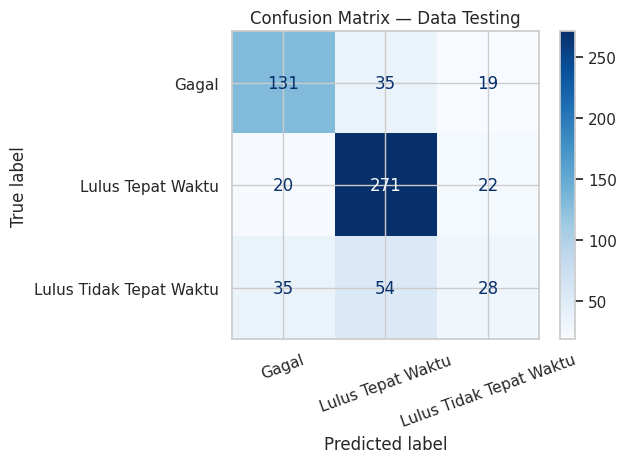

F1-macro training: 0.9519
F1-macro testing : 0.6042
Selisih F1 training-testing: 0.3477


In [ ]:
# Task 9 — Evaluasi pada data testing
from sklearn.metrics import (accuracy_score, precision_score, recall_score, f1_score,
                             classification_report, confusion_matrix, ConfusionMatrixDisplay)

y_pred = model.predict(X_test)
akurasi = accuracy_score(y_test, y_pred)
presisi = precision_score(y_test, y_pred, average="macro", zero_division=0)
recall = recall_score(y_test, y_pred, average="macro", zero_division=0)
f1 = f1_score(y_test, y_pred, average="macro", zero_division=0)

hasil = pd.DataFrame({
    "Metrik": ["Accuracy", "Precision macro", "Recall macro", "F1-score macro"],
    "Nilai": [akurasi, presisi, recall, f1]
})
display(hasil.round(4))

print("Classification report:")
print(classification_report(y_test, y_pred, zero_division=0))

cm = confusion_matrix(y_test, y_pred, labels=model.classes_)
disp = ConfusionMatrixDisplay(confusion_matrix=cm, display_labels=model.classes_)
disp.plot(cmap="Blues", xticks_rotation=20, values_format="d")
plt.title("Confusion Matrix — Data Testing")
plt.tight_layout()
plt.show()

# Bandingkan skor training dan testing untuk indikasi overfitting.
pred_train = model.predict(X_train)
f1_train = f1_score(y_train, pred_train, average="macro", zero_division=0)
print(f"F1-macro training: {f1_train:.4f}")
print(f"F1-macro testing : {f1:.4f}")
print(f"Selisih F1 training-testing: {f1_train-f1:.4f}")

## Task 10 — Kesimpulan

Model klasifikasi yang digunakan adalah **Random Forest Classifier** dengan penanganan ketidakseimbangan kelas melalui `class_weight='balanced'`. Data dibagi secara stratified dengan rasio 80% training dan 20% testing, dan model dievaluasi menggunakan Stratified 5-Fold Cross-Validation serta metrik accuracy, precision, recall, F1-score, dan confusion matrix.

Model ini merupakan alat bantu keputusan, bukan penentu mutlak keberhasilan mahasiswa. Penggunaannya perlu disertai evaluasi berkala, perlindungan data pribadi, dan penilaian wali akademik.
